# Predictive Insight Engine
**House Price Prediction**

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

data = pd.read_excel("RealEstate_HousePrice_Dataset_4200.xlsx")
print(data.head())
print("Dataset shape:", data.shape)
print(data.isnull().sum())

   house_id  area_sqft  bedrooms  bathrooms  location_score  age_years  \
0    100001       1973         5          4             7.6         23   
1    100002       1560         3          3             6.3         13   
2    100003       2071         4          3             5.8          9   
3    100004       2640         5          3             7.7         12   
4    100005       1498         3          3             3.8         15   

   distance_city_km  lot_size_sqft  has_garage  has_pool  \
0              11.9           5220           1         0   
1              15.8           3882           1         0   
2              21.1           4488           0         0   
3               7.9           3614           1         1   
4              24.0           2663           0         0   

   renovation_years_ago  house_price_inr  
0                     0         40275084  
1                    13         26812029  
2                     9         29315677  
3                     

## Part B — Features aur target select karna

In [6]:
features = [
    "area_sqft", "bedrooms", "bathrooms", "location_score", "age_years",
    "distance_city_km", "lot_size_sqft", "has_garage", "has_pool",
    "renovation_years_ago"
]
X = data[features]
y = data["house_price_inr"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 3360
Testing rows: 840


## Part C — Simple Linear Regression

Slope: 14788.306111307536
Intercept: -1163519.1764186025


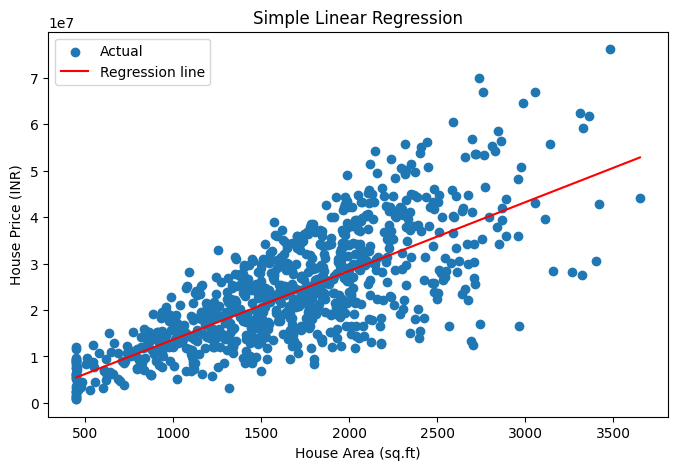

In [7]:
simple_model = LinearRegression()
simple_model.fit(X_train[["area_sqft"]], y_train)
simple_predictions = simple_model.predict(X_test[["area_sqft"]])

print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

plot_data = pd.DataFrame({
    "area_sqft": X_test["area_sqft"],
    "actual_price": y_test,
    "predicted_price": simple_predictions
}).sort_values("area_sqft")

plt.figure(figsize=(8, 5))
plt.scatter(plot_data["area_sqft"], plot_data["actual_price"], label="Actual")
plt.plot(plot_data["area_sqft"], plot_data["predicted_price"], color="red", label="Regression line")
plt.xlabel("House Area (sq.ft)")
plt.ylabel("House Price (INR)")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

## Part D — Evaluation metrics

In [8]:
def show_metrics(model_name, actual, predicted, number_of_features):
    mse = mean_squared_error(actual, predicted)
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    n = len(actual)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - number_of_features - 1)

    print("\\n" + model_name)
    print("MSE:", round(mse, 2))
    print("MAE:", round(mae, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))
    print("Adjusted R2 Score:", round(adjusted_r2, 4))

## Part E — Multiple Linear Regression

\nMultiple Linear Regression
MSE: 12592918884127.74
MAE: 2604991.41
RMSE: 3548650.29
R2 Score: 0.9178
Adjusted R2 Score: 0.9168


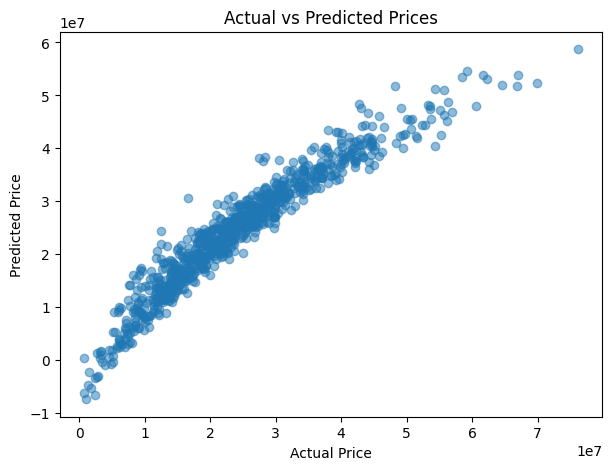

In [9]:
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)
multiple_predictions = multiple_model.predict(X_test)
show_metrics("Multiple Linear Regression", y_test, multiple_predictions, len(features))

plt.figure(figsize=(7, 5))
plt.scatter(y_test, multiple_predictions, alpha=0.5)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Prices")
plt.show()

## Part F — Polynomial Regression

In [10]:
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train[["area_sqft"]])
X_test_poly = poly.transform(X_test[["area_sqft"]])

poly_model = LinearRegression()
poly_model.fit(X_train_poly, y_train)
poly_predictions = poly_model.predict(X_test_poly)
show_metrics("Polynomial Regression (degree 2)", y_test, poly_predictions, 2)

\nPolynomial Regression (degree 2)
MSE: 66962947122198.46
MAE: 6292394.56
RMSE: 8183089.09
R2 Score: 0.5627
Adjusted R2 Score: 0.5616


## Part G — Basic Gradient Descent from scratch

\nGradient Descent (area only)
MSE: 66989260028153.05
MAE: 6294593.7
RMSE: 8184696.7
R2 Score: 0.5625
Adjusted R2 Score: 0.562


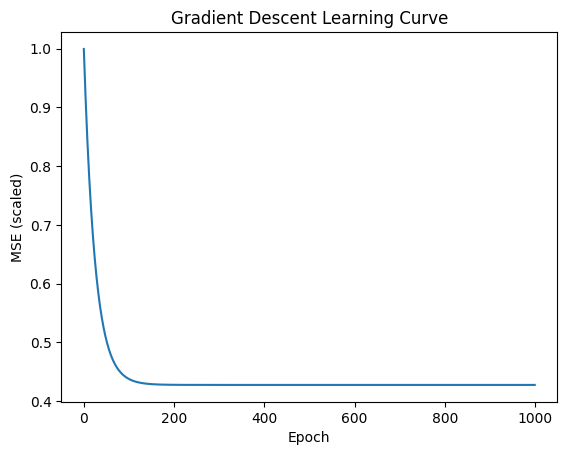

In [11]:
area_mean = X_train["area_sqft"].mean()
area_std = X_train["area_sqft"].std()
price_mean = y_train.mean()
price_std = y_train.std()

x = (X_train["area_sqft"].to_numpy() - area_mean) / area_std
y_scaled = (y_train.to_numpy() - price_mean) / price_std
x_test_scaled = (X_test["area_sqft"].to_numpy() - area_mean) / area_std

weight = 0.0
bias = 0.0
learning_rate = 0.01
epochs = 1000
loss_history = []

for epoch in range(epochs):
    prediction = weight * x + bias
    error = prediction - y_scaled
    weight_gradient = 2 * np.mean(error * x)
    bias_gradient = 2 * np.mean(error)
    weight -= learning_rate * weight_gradient
    bias -= learning_rate * bias_gradient
    loss_history.append(np.mean(error ** 2))

gd_predictions = (weight * x_test_scaled + bias) * price_std + price_mean
show_metrics("Gradient Descent (area only)", y_test, gd_predictions, 1)

plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.title("Gradient Descent Learning Curve")
plt.show()

## Final comparison

In [12]:
show_metrics("Simple Linear Regression", y_test, simple_predictions, 1)
show_metrics("Multiple Linear Regression", y_test, multiple_predictions, len(features))
show_metrics("Polynomial Regression", y_test, poly_predictions, 2)
show_metrics("Gradient Descent", y_test, gd_predictions, 1)

print("Compare test RMSE and R2. Lower RMSE and higher R2 are generally better.")

\nSimple Linear Regression
MSE: 66989260021849.47
MAE: 6294593.7
RMSE: 8184696.7
R2 Score: 0.5625
Adjusted R2 Score: 0.562
\nMultiple Linear Regression
MSE: 12592918884127.74
MAE: 2604991.41
RMSE: 3548650.29
R2 Score: 0.9178
Adjusted R2 Score: 0.9168
\nPolynomial Regression
MSE: 66962947122198.46
MAE: 6292394.56
RMSE: 8183089.09
R2 Score: 0.5627
Adjusted R2 Score: 0.5616
\nGradient Descent
MSE: 66989260028153.05
MAE: 6294593.7
RMSE: 8184696.7
R2 Score: 0.5625
Adjusted R2 Score: 0.562
Compare test RMSE and R2. Lower RMSE and higher R2 are generally better.
